# How Are In-Demand Skills Trending For Data Analysts ?

In [152]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)



In [153]:
df_DA_US = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

In [154]:
df_DA_US['job_posted_month_no'] = df_DA_US['job_posted_date'].dt.month

In [155]:
df_DA_US_explode = df_DA_US.explode('job_skills')

In [156]:
df_DA_US_pivot = df_DA_US_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc=['size'], fill_value=0)

df_DA_US_pivot.loc['Total'] = df_DA_US_pivot.sum()

In [157]:
df_DA_US_pivot

size                                                  \
job_skills          airflow airtable alteryx angular ansible apl arch asana   
job_posted_month_no                                                           
1                        12        0      53       0       1   0    0     1   
2                        13        0      34       1       2   0    0     4   
3                        11        0      41       1       3   0    0     6   
4                         5        0      57       1       0   0    0     1   
5                         6        1      35       0       3   0    0     1   
6                        10        3      33       1       1   0    2     0   
7                        13        0      33       0       1   0    0     1   
8                         9        2      29       0       0   0    0     0   
9                         7        0      19       1       0   1    0     2   
10                        7        3      16       1       0   0    1     0   
11                        6        0      24       0       0   0    0     0   
12                        4        0      16       3       1   0    1     1   
Total                   103        9     390       9      12   1    4    17   

                                      ...                                  \
job_skills          asp.net assembly  ... vmware vue watson webex windows   
job_posted_month_no                   ...                                   
1                         1        8  ...      2   0      0     2      10   
2                         2        7  ...      0   5      1     1      21   
3                         2        4  ...      1   2      0     2      14   
4                         0        1  ...      2   0      0     1      24   
5                         2        1  ...      0   0      0     1      20   
6                         0        4  ...      1   0      0     0      15   
7                         0        4  ...      0   0      0     0      15   
8                         0       14  ...      0   0      0     1      15   
9                         0        0  ...      2   0      0     0      11   
10                        1        3  ...      0   0      0     0      10   
11                        2        3  ...      0   0      1     3       6   
12                        0        6  ...      0   1      0     0       8   
Total                    10       55  ...      8   8      2    11     169   

                                                    
job_skills          wire  word workfront yarn zoom  
job_posted_month_no                                 
1                      0   169         0    0    3  
2                      1   128         0    0    2  
3                      3   142         0    0    4  
4                      4   143         1    0    2  
5                      0    92         0    0    1  
6                      2   126         0    0    2  
7                      2   101         0    1    0  
8                      1   112         0    0    5  
9                      0    65         0    0    2  
10                     0    76         0    0    1  
11                     0    61         0    0    1  
12                     0    85         2    0    5  
Total                 13  1300         3    1   28  

[13 rows x 188 columns]

In [158]:
df_DA_US_pivot.loc['Total'].sort_values(ascending=False)

      job_skills
size  sql           8305
      excel         5829
      tableau       4592
      python        4238
      power bi      2933
                    ... 
      svelte           1
      theano           1
      tidyr            1
      symphony         1
      yarn             1
Name: Total, Length: 188, dtype: int64

In [159]:
df_DA_US_pivot[df_DA_US_pivot.loc['Total'].sort_values(ascending=False).index]

size                                                  \
job_skills            sql excel tableau python power bi   sas     r  word   
job_posted_month_no                                                         
1                    1138   781     646    529      326   394   338   169   
2                     782   544     408    378      302   270   233   128   
3                     802   580     463    400      277   300   241   142   
4                     845   577     462    421      292   258   238   143   
5                     706   490     367    336      251   206   219    92   
6                     742   491     395    396      272   202   252   126   
7                     560   431     296    292      190   182   188   101   
8                     784   641     480    460      292   272   321   112   
9                     485   336     277    253      183   150   157    65   
10                    556   343     308    270      207   150   154    76   
11                    472   291     246    234      168   146   120    61   
12                    433   324     244    269      173   174   169    85   
Total                8305  5829    4592   4238     2933  2704  2630  1300   

                                       ...                                    \
job_skills          powerpoint oracle  ... mariadb mxnet next.js ringcentral   
job_posted_month_no                    ...                                     
1                          176    164  ...       0     0       0           1   
2                          130     99  ...       0     0       0           0   
3                          127    107  ...       0     0       0           0   
4                          133    122  ...       0     0       0           0   
5                          119     98  ...       1     0       0           0   
6                          116     99  ...       0     0       0           0   
7                          101     62  ...       0     0       1           0   
8                          133     98  ...       0     0       0           0   
9                           53     67  ...       0     0       0           0   
10                          71     66  ...       0     0       0           0   
11                          57     55  ...       0     0       0           0   
12                          69     42  ...       0     1       0           0   
Total                     1285   1079  ...       1     1       1           1   

                                                                 
job_skills          sqlserver svelte theano tidyr symphony yarn  
job_posted_month_no                                              
1                           0      0      0     0        0    0  
2                           0      0      0     0        0    0  
3                           0      0      0     0        0    0  
4                           0      0      0     0        0    0  
5                           0      0      0     0        0    0  
6                           0      0      0     0        0    0  
7                           1      0      0     0        0    1  
8                           0      0      0     0        0    0  
9                           0      0      0     0        1    0  
10                          0      0      0     1        0    0  
11                          0      0      0     0        0    0  
12                          0      1      1     0        0    0  
Total                       1      1      1     1        1    1  

[13 rows x 188 columns]

In [160]:
df_DA_US_pivot = df_DA_US_pivot[df_DA_US_pivot.loc['Total'].sort_values(ascending=False).index]

#### now delete The Total Row , we use it and now we dont need it .

In [161]:
df_DA_US_pivot = df_DA_US_pivot.drop('Total')

In [162]:
df_DA_US_pivot

size                                               \
job_skills            sql excel tableau python power bi  sas    r word   
job_posted_month_no                                                      
1                    1138   781     646    529      326  394  338  169   
2                     782   544     408    378      302  270  233  128   
3                     802   580     463    400      277  300  241  142   
4                     845   577     462    421      292  258  238  143   
5                     706   490     367    336      251  206  219   92   
6                     742   491     395    396      272  202  252  126   
7                     560   431     296    292      190  182  188  101   
8                     784   641     480    460      292  272  321  112   
9                     485   336     277    253      183  150  157   65   
10                    556   343     308    270      207  150  154   76   
11                    472   291     246    234      168  146  120   61   
12                    433   324     244    269      173  174  169   85   

                                       ...                                    \
job_skills          powerpoint oracle  ... mariadb mxnet next.js ringcentral   
job_posted_month_no                    ...                                     
1                          176    164  ...       0     0       0           1   
2                          130     99  ...       0     0       0           0   
3                          127    107  ...       0     0       0           0   
4                          133    122  ...       0     0       0           0   
5                          119     98  ...       1     0       0           0   
6                          116     99  ...       0     0       0           0   
7                          101     62  ...       0     0       1           0   
8                          133     98  ...       0     0       0           0   
9                           53     67  ...       0     0       0           0   
10                          71     66  ...       0     0       0           0   
11                          57     55  ...       0     0       0           0   
12                          69     42  ...       0     1       0           0   

                                                                 
job_skills          sqlserver svelte theano tidyr symphony yarn  
job_posted_month_no                                              
1                           0      0      0     0        0    0  
2                           0      0      0     0        0    0  
3                           0      0      0     0        0    0  
4                           0      0      0     0        0    0  
5                           0      0      0     0        0    0  
6                           0      0      0     0        0    0  
7                           1      0      0     0        0    1  
8                           0      0      0     0        0    0  
9                           0      0      0     0        1    0  
10                          0      0      0     1        0    0  
11                          0      0      0     0        0    0  
12                          0      1      1     0        0    0  

[12 rows x 188 columns]

<Axes: xlabel='job_posted_month_no'>

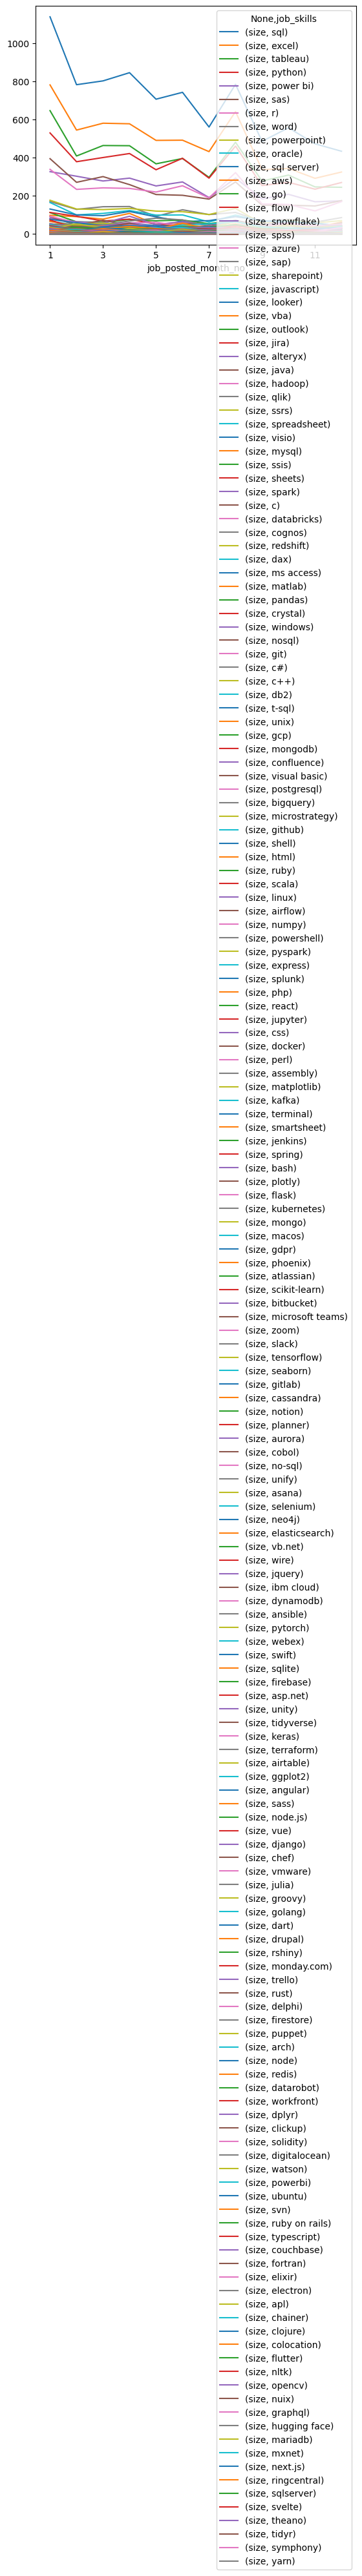

In [163]:
df_DA_US_pivot.plot(kind='line')

#### Now we want the persentage of each skill per month .

In [164]:
DA_totals = df_DA_US.groupby('job_posted_month_no').size()

In [165]:
DA_totals

job_posted_month_no
1     1816
2     1284
3     1362
4     1369
5     1156
6     1207
7      955
8     1414
9      856
10    1002
11     848
12     817
dtype: int64

In [166]:
df_DA_US_percent = df_DA_US_pivot.div(DA_totals / 100, axis=0)

In [167]:
df_DA_US_percent

size                                              \
job_skills                 sql      excel    tableau     python   power bi   
job_posted_month_no                                                          
1                    62.665198  43.006608  35.572687  29.129956  17.951542   
2                    60.903427  42.367601  31.775701  29.439252  23.520249   
3                    58.883994  42.584435  33.994126  29.368576  20.337739   
4                    61.723886  42.147553  33.747261  30.752374  21.329438   
5                    61.072664  42.387543  31.747405  29.065744  21.712803   
6                    61.474731  40.679370  32.725766  32.808616  22.535211   
7                    58.638743  45.130890  30.994764  30.575916  19.895288   
8                    55.445545  45.332390  33.946252  32.531825  20.650636   
9                    56.658879  39.252336  32.359813  29.556075  21.378505   
10                   55.489022  34.231537  30.738523  26.946108  20.658683   
11                   55.660377  34.316038  29.009434  27.594340  19.811321   
12                   52.998776  39.657283  29.865361  32.925337  21.175031   

                                                                           \
job_skills                 sas          r       word powerpoint    oracle   
job_posted_month_no                                                         
1                    21.696035  18.612335   9.306167   9.691630  9.030837   
2                    21.028037  18.146417   9.968847  10.124611  7.710280   
3                    22.026432  17.694567  10.425844   9.324523  7.856094   
4                    18.845873  17.384953  10.445581   9.715121  8.911614   
5                    17.820069  18.944637   7.958478  10.294118  8.477509   
6                    16.735708  20.878210  10.439105   9.610605  8.202154   
7                    19.057592  19.685864  10.575916  10.575916  6.492147   
8                    19.236209  22.701556   7.920792   9.405941  6.930693   
9                    17.523364  18.341121   7.593458   6.191589  7.827103   
10                   14.970060  15.369261   7.584830   7.085828  6.586826   
11                   17.216981  14.150943   7.193396   6.721698  6.485849   
12                   21.297430  20.685435  10.403917   8.445532  5.140759   

                     ...                                                      \
job_skills           ...   mariadb     mxnet   next.js ringcentral sqlserver   
job_posted_month_no  ...                                                       
1                    ...  0.000000  0.000000  0.000000    0.055066  0.000000   
2                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
3                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
4                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
5                    ...  0.086505  0.000000  0.000000    0.000000  0.000000   
6                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
7                    ...  0.000000  0.000000  0.104712    0.000000  0.104712   
8                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
9                    ...  0.000000  0.000000  0.000000    0.000000  0.000000   
10                   ...  0.000000  0.000000  0.000000    0.000000  0.000000   
11                   ...  0.000000  0.000000  0.000000    0.000000  0.000000   
12                   ...  0.000000  0.122399  0.000000    0.000000  0.000000   

                                                                     
job_skills             svelte    theano   tidyr  symphony      yarn  
job_posted_month_no                                                  
1                    0.000000  0.000000  0.0000  0.000000  0.000000  
2                    0.000000  0.000000  0.0000  0.000000  0.000000  
3                    0.000000  0.000000  0.0000  0.000000  0.000000  
4                    0.000000  0.000000  0.0000  0.000000  0.000000  
5       

#### changes month number to month name

In [168]:

df_DA_US_percent = df_DA_US_percent.reset_index()
df_DA_US_percent['job_posted_month'] = df_DA_US_percent['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_US_percent = df_DA_US_percent.set_index('job_posted_month')
df_DA_US_percent = df_DA_US_percent.drop(columns='job_posted_month_no')

C:\Users\abdel\AppData\Local\Temp\ipykernel_12688\4183705403.py:4: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  df_DA_US_percent = df_DA_US_percent.drop(columns='job_posted_month_no')


In [169]:
df_DA_US_percent

size                                              \
job_skills              sql      excel    tableau     python   power bi   
job_posted_month                                                          
Jan               62.665198  43.006608  35.572687  29.129956  17.951542   
Feb               60.903427  42.367601  31.775701  29.439252  23.520249   
Mar               58.883994  42.584435  33.994126  29.368576  20.337739   
Apr               61.723886  42.147553  33.747261  30.752374  21.329438   
May               61.072664  42.387543  31.747405  29.065744  21.712803   
Jun               61.474731  40.679370  32.725766  32.808616  22.535211   
Jul               58.638743  45.130890  30.994764  30.575916  19.895288   
Aug               55.445545  45.332390  33.946252  32.531825  20.650636   
Sep               56.658879  39.252336  32.359813  29.556075  21.378505   
Oct               55.489022  34.231537  30.738523  26.946108  20.658683   
Nov               55.660377  34.316038  29.009434  27.594340  19.811321   
Dec               52.998776  39.657283  29.865361  32.925337  21.175031   

                                                                        ...  \
job_skills              sas          r       word powerpoint    oracle  ...   
job_posted_month                                                        ...   
Jan               21.696035  18.612335   9.306167   9.691630  9.030837  ...   
Feb               21.028037  18.146417   9.968847  10.124611  7.710280  ...   
Mar               22.026432  17.694567  10.425844   9.324523  7.856094  ...   
Apr               18.845873  17.384953  10.445581   9.715121  8.911614  ...   
May               17.820069  18.944637   7.958478  10.294118  8.477509  ...   
Jun               16.735708  20.878210  10.439105   9.610605  8.202154  ...   
Jul               19.057592  19.685864  10.575916  10.575916  6.492147  ...   
Aug               19.236209  22.701556   7.920792   9.405941  6.930693  ...   
Sep               17.523364  18.341121   7.593458   6.191589  7.827103  ...   
Oct               14.970060  15.369261   7.584830   7.085828  6.586826  ...   
Nov               17.216981  14.150943   7.193396   6.721698  6.485849  ...   
Dec               21.297430  20.685435  10.403917   8.445532  5.140759  ...   

                                                                      \
job_skills         mariadb     mxnet   next.js ringcentral sqlserver   
job_posted_month                                                       
Jan               0.000000  0.000000  0.000000    0.055066  0.000000   
Feb               0.000000  0.000000  0.000000    0.000000  0.000000   
Mar               0.000000  0.000000  0.000000    0.000000  0.000000   
Apr               0.000000  0.000000  0.000000    0.000000  0.000000   
May               0.086505  0.000000  0.000000    0.000000  0.000000   
Jun               0.000000  0.000000  0.000000    0.000000  0.000000   
Jul               0.000000  0.000000  0.104712    0.000000  0.104712   
Aug               0.000000  0.000000  0.000000    0.000000  0.000000   
Sep               0.000000  0.000000  0.000000    0.000000  0.000000   
Oct               0.000000  0.000000  0.000000    0.000000  0.000000   
Nov               0.000000  0.000000  0.000000    0.000000  0.000000   
Dec               0.000000  0.122399  0.000000    0.000000  0.000000   

                                                                  
job_skills          svelte    theano   tidyr  symphony      yarn  
job_posted_month                                                  
Jan               0.000000  0.000000  0.0000  0.000000  0.000000  
Feb               0.000000  0.000000  0.0000  0.000000  0.000000  
Mar               0.000000  0.000000  0.0000  0.000000  0.000000  
Apr               0.000000  0.000000  0.0000  0.000000  0.000000  
May               0.000000  0.000000  0.0000  0.000000  0.000000  
Jun               0.000000  0.000000  0.0000  0.000000  0.000000  
Jul               0.000000 

#### Now I Want The First 5 Values .

In [176]:
df_DA_US_percent.iloc[:, :5]

size                                            
job_skills              sql      excel    tableau     python   power bi
job_posted_month                                                       
Jan               62.665198  43.006608  35.572687  29.129956  17.951542
Feb               60.903427  42.367601  31.775701  29.439252  23.520249
Mar               58.883994  42.584435  33.994126  29.368576  20.337739
Apr               61.723886  42.147553  33.747261  30.752374  21.329438
May               61.072664  42.387543  31.747405  29.065744  21.712803
Jun               61.474731  40.679370  32.725766  32.808616  22.535211
Jul               58.638743  45.130890  30.994764  30.575916  19.895288
Aug               55.445545  45.332390  33.946252  32.531825  20.650636
Sep               56.658879  39.252336  32.359813  29.556075  21.378505
Oct               55.489022  34.231537  30.738523  26.946108  20.658683
Nov               55.660377  34.316038  29.009434  27.594340  19.811321
Dec               52.998776  39.657283  29.865361  32.925337  21.175031

In [171]:
df_plot = df_DA_US_percent.iloc[:,:5]

In [173]:
df_plot.columns = df_plot.columns.get_level_values(-1)


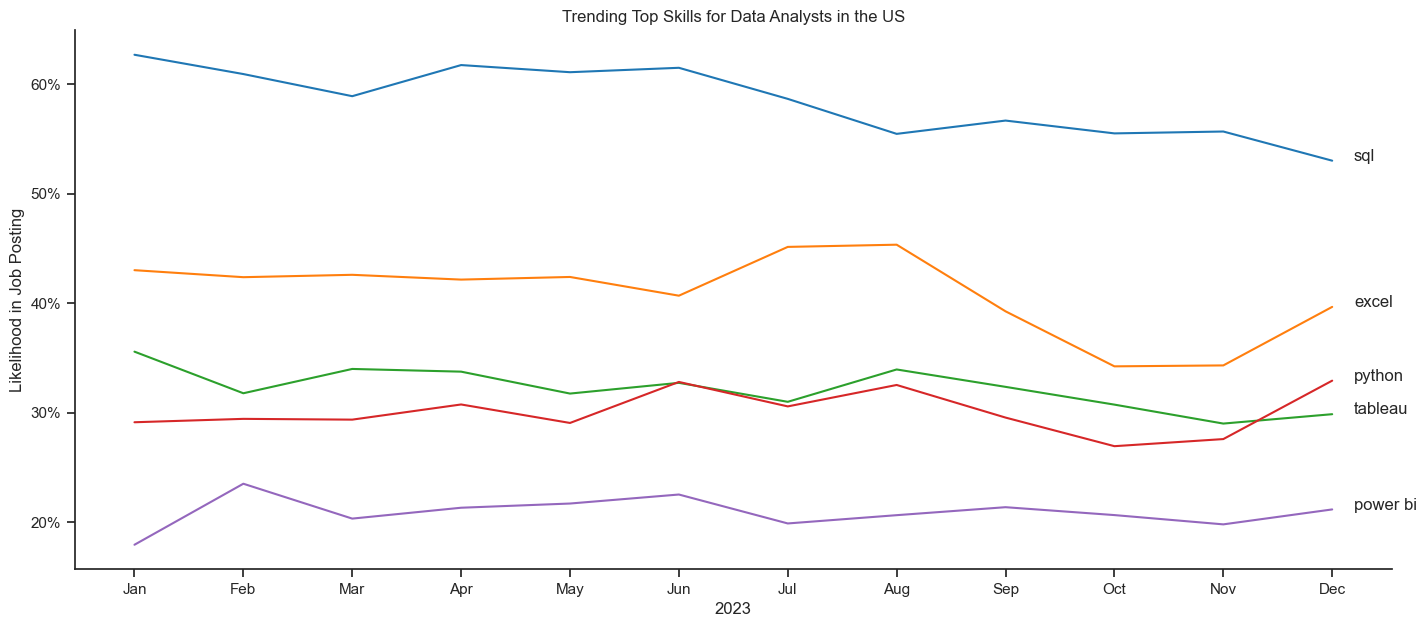

In [201]:
sns.set_theme(style='ticks')
plt.figure(figsize=(17, 7))

sns.lineplot(data=df_plot, dashes=False, palette='tab10', legend=False)
sns.despine()

from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')

for i in range(5):    
    plt.text(11.2, df_plot.iloc[-1, i], df_plot.columns[i])
